<a href="https://colab.research.google.com/github/NoelAR1103/in-silico-D-T-P/blob/main/D1DTP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install biopython
import Bio
print("setup successfull! Biopython version:", Bio.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 49.1 MB/s  0:00:00
setup successfull! Biopython version: 1.88


In [3]:
# Our single target pathogen
pathogen = "Acinetobacter baumannii"

# A real Beta-lactamase resistance protein sequence from A. baumannii
protein_seq = "MRVLALSAVFLVASIIGMPAVAKEWQENKSWNAHFTEHKSQGVVVLWNENKQQGFTNNLKRANQAFLPASTFKIPNSLIALDLGVVKDEHQVFKWDGQTRDIATWNRDHNLITAMKYSVVPVYQEFARQIGEARMSKMLHAFDYGNEDISGNVDSFWLDGGIRISATEQISFLRKLYHNKLHVSERSQRI"

# Let's inspect the protein
print("Target:", pathogen)
print("Length (amino acids):", len(protein_seq))
print("Cysteine count:", protein_seq.count("C"))
print("Alanine count:", protein_seq.count("A"))

Target: Acinetobacter baumannii
Length (amino acids): 190
Cysteine count: 0
Alanine count: 16


In [4]:
import urllib.request
from Bio import SeqIO

# 1. Download a real A. baumannii carbapenemase protein (OXA-23) in FASTA format
uniprot_id = "Q9L4P2"
url = f"https://rest.uniprot.org/uniprotkb/{uniprot_id}.fasta"
urllib.request.urlretrieve(url, "oxa23.fasta")

# 2. Use Biopython to read the downloaded FASTA file
record = SeqIO.read("oxa23.fasta", "fasta")

print("Protein ID:", record.id)
print("Description:", record.description)
print("Full Length:", len(record.seq))
print("First 30 amino acids:", record.seq[:30])

Protein ID: sp|Q9L4P2|BLO23_ACIBA
Description: sp|Q9L4P2|BLO23_ACIBA Beta-lactamase OXA-23 OS=Acinetobacter baumannii OX=470 GN=OXA-23 PE=1 SV=1
Full Length: 273
First 30 amino acids: MNKYFTCYVVASLFLSGCTVQHNLINETPS


In [5]:
import urllib.request
from Bio import SeqIO

# 1. Download ALL reviewed (Swiss-Prot) proteins for Acinetobacter baumannii (TaxID: 470)
url = "https://rest.uniprot.org/uniprotkb/stream?format=fasta&query=(taxonomy_id:470)+AND+(reviewed:true)"
urllib.request.urlretrieve(url, "abaumannii_reviewed.fasta")

# 2. Parse all records into a Python list
all_proteins = list(SeqIO.parse("abaumannii_reviewed.fasta", "fasta"))
print("Total reviewed A. baumannii proteins downloaded:", len(all_proteins))

# 3. FILTER #1: Keep only proteins >= 100 amino acids (capable of forming stable drug-binding pockets)
filtered_proteins = []

for protein in all_proteins:
    if len(protein.seq) >= 100:
        filtered_proteins.append(protein)

print("Proteins passing Length Filter (>= 100 aa):", len(filtered_proteins))
print("Proteins eliminated (too small):", len(all_proteins) - len(filtered_proteins))

Total reviewed A. baumannii proteins downloaded: 1845
Proteins passing Length Filter (>= 100 aa): 1676
Proteins eliminated (too small): 169


In [6]:
from Bio import SeqIO

# 1. Remove exact duplicate sequences (Non-redundant proteome)
seen_sequences = set()
unique_proteins = []

for protein in filtered_proteins:
    seq_str = str(protein.seq)
    if seq_str not in seen_sequences:
        seen_sequences.add(seq_str)
        unique_proteins.append(protein)

print("Proteins before deduplication:", len(filtered_proteins))
print("Unique non-redundant proteins:", len(unique_proteins))
print("Duplicates removed:", len(filtered_proteins) - len(unique_proteins))

# 2. Save our surviving candidates to a new FASTA file for the next stage
SeqIO.write(unique_proteins, "filter2_unique.fasta", "fasta")
print("Saved successfully to filter2_unique.fasta!")

Proteins before deduplication: 1676
Unique non-redundant proteins: 766
Duplicates removed: 910
Saved successfully to filter2_unique.fasta!


In [11]:
from Bio import SeqIO

# 1. Download compressed Human proteome (.fasta.gz) and build human_db properly
!curl -f -L --retry 3 "https://rest.uniprot.org/uniprotkb/stream?compressed=true&format=fasta&query=(taxonomy_id:9606)+AND+(reviewed:true)" -o human_proteome.fasta.gz
!gunzip -f human_proteome.fasta.gz
!makeblastdb -in human_proteome.fasta -dbtype prot -out human_db

# 2. Run BLASTP against the newly built human_db
!blastp -query filter2_unique.fasta -db human_db -evalue 1e-4 -outfmt 6 -max_target_seqs 1 -num_threads 2 -out blast_human_results.txt

# 3. Filter out human homologs
human_homolog_ids = set()
with open("blast_human_results.txt", "r") as f:
    for line in f:
        human_homolog_ids.add(line.split("\t")[0])

non_homologous_proteins = [p for p in unique_proteins if p.id not in human_homolog_ids]

print("Total unique A. baumannii proteins:", len(unique_proteins))
print("Human homologs eliminated (toxic risk):", len(human_homolog_ids))
print("Safe Non-Homologous targets remaining:", len(non_homologous_proteins))

SeqIO.write(non_homologous_proteins, "filter3_non_human.fasta", "fasta")
print("Saved safely to filter3_non_human.fasta!")

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 7331k    0 7331k    0     0   584k      0 --:--:--  0:00:12 --:--:--  998k


Building a new DB, current time: 11/12/2026 11:47:08
New DB name:   /content/human_db
New DB title:  human_proteome.fasta
Sequence type: Protein
Keep MBits: T
Maximum file size: 1000000000B
Adding sequences from FASTA; added 20430 sequences in 0.420329 seconds.


Total unique A. baumannii proteins: 766
Human homologs eliminated (toxic risk): 398
Safe Non-Homologous targets remaining: 368
Saved safely to filter3_non_human.fasta!


In [12]:
from Bio import SeqIO

# 1. Download curated Gram-negative core essential survival proteins (compressed .gz)
!curl -f -L --retry 3 "https://rest.uniprot.org/uniprotkb/stream?compressed=true&format=fasta&query=(taxonomy_id:83333)+AND+(reviewed:true)+AND+(go:0009252+OR+go:0006260+OR+go:0009245+OR+go:0006412)" -o essential_ref.fasta.gz
!gunzip -f essential_ref.fasta.gz

# 2. Build local BLAST database of essential survival proteins
!makeblastdb -in essential_ref.fasta -dbtype prot -out essential_db

# 3. BLAST our 368 Non-Human A. baumannii proteins against the Essential database
!blastp -query filter3_non_human.fasta -db essential_db -evalue 1e-10 -outfmt 6 -max_target_seqs 1 -num_threads 2 -out blast_essential_results.txt

# 4. Keep ONLY the proteins that matched an essential survival protein
essential_ids = set()
with open("blast_essential_results.txt", "r") as f:
    for line in f:
        essential_ids.add(line.split("\t")[0])

essential_targets = [p for p in non_homologous_proteins if p.id in essential_ids]

print("Day 7 Non-Homologous inputs:", len(non_homologous_proteins))
print("Essential survival drug targets found:", len(essential_targets))

SeqIO.write(essential_targets, "filter4_essential.fasta", "fasta")
print("Saved to filter4_essential.fasta!")

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 90946    0 90946    0     0   2586      0 --:--:--  0:00:35 --:--:-- 11285


Building a new DB, current time: 11/12/2026 11:49:30
New DB name:   /content/essential_db
New DB title:  essential_ref.fasta
Sequence type: Protein
Deleted existing Protein BLAST database named /content/essential_db
Keep MBits: T
Maximum file size: 1000000000B
Adding sequences from FASTA; added 483 sequences in 0.00859213 seconds.


Day 7 Non-Homologous inputs: 368
Essential survival drug targets found: 56
Saved to filter4_essential.fasta!


In [13]:
import pandas as pd
import requests
from Bio import SeqIO

# 1. Extract UniProt Accession IDs from our 56 surviving targets
essential_records = list(SeqIO.parse("filter4_essential.fasta", "fasta"))
accessions = [rec.id.split("|")[1] for rec in essential_records]

print(f"Fetching functional & subcellular annotations for {len(accessions)} targets...")

# 2. Query UniProt API in batch for Protein Name, Gene Name, Length, and Subcellular Location
url = "https://rest.uniprot.org/uniprotkb/accessions"
params = {
    "accessions": ",".join(accessions),
    "fields": "accession,gene_primary,protein_name,length,cc_subcellular_location",
    "format": "tsv"
}

response = requests.get(url, params=params)
with open("targets_annotated.tsv", "w") as f:
    f.write(response.text)

# 3. Load into a Pandas DataFrame and inspect the top 15 targets
df = pd.read_csv("targets_annotated.tsv", sep="\t")
df.columns = ["UniProt_ID", "Gene", "Protein_Name", "Length", "Subcellular_Location"]

# Fill missing subcellular annotations cleanly
df["Subcellular_Location"] = df["Subcellular_Location"].fillna("Not specified in UniProt")

print("\n--- TOP 15 ESSENTIAL NON-HOMOLOGOUS DRUG TARGETS ---")
display(df.head(15))

# Save full table to CSV
df.to_csv("shortlisted_56_targets.csv", index=False)
print("\nFull 56-target table saved to shortlisted_56_targets.csv!")

Fetching functional & subcellular annotations for 56 targets...

--- TOP 15 ESSENTIAL NON-HOMOLOGOUS DRUG TARGETS ---


,UniProt_ID,Gene,Protein_Name,Length,Subcellular_Location
0,D0C8Z9,mrdA,"Peptidoglycan D,D-transpeptidase MrdA (EC 3.4....",672,SUBCELLULAR LOCATION: Cell inner membrane {ECO...
1,A3M0Q4,dnaA,Chromosomal replication initiator protein DnaA,465,SUBCELLULAR LOCATION: Cytoplasm {ECO:0000255|H...
2,A3M1C6,murD,UDP-N-acetylmuramoylalanine--D-glutamate ligas...,448,SUBCELLULAR LOCATION: Cytoplasm {ECO:0000255|H...
3,A3M3C7,mtgA,Biosynthetic peptidoglycan transglycosylase (E...,225,SUBCELLULAR LOCATION: Cell inner membrane {ECO...
4,A3M4U7,ruvC,Crossover junction endodeoxyribonuclease RuvC ...,181,SUBCELLULAR LOCATION: Cytoplasm {ECO:0000255|H...
5,A3M649,fabZ,3-hydroxyacyl-[acyl-carrier-protein] dehydrata...,146,SUBCELLULAR LOCATION: Cytoplasm {ECO:0000255|H...
6,A3M9Y1,murG,UDP-N-acetylglucosamine--N-acetylmuramyl-(pent...,365,SUBCELLULAR LOCATION: Cell inner membrane {ECO...
7,B0V744,murB,UDP-N-acetylenolpyruvoylglucosamine reductase ...,353,SUBCELLULAR LOCATION: Cytoplasm {ECO:0000255|H...
8,B0V8P2,mraY,Phospho-N-acetylmuramoyl-pentapeptide-transfer...,372,SUBCELLULAR LOCATION: Cell inner membrane {ECO...
9,B0V9F5,murG,UDP-N-acetylglucosamine--N-acetylmuramyl-(pent...,365,SUBCELLULAR LOCATION: Cell inner membrane {ECO...



Full 56-target table saved to shortlisted_56_targets.csv!


In [14]:
import pandas as pd
import requests

# 1. Collapse multi-strain duplicates so each unique Gene appears once
unique_gene_df = df.drop_duplicates(subset=["Gene"]).copy()
print(f"Unique gene targets after collapsing strain variants: {len(unique_gene_df)}")

# 2. Query UniProt for DrugBank, ChEMBL, and 3D Crystal Structure (PDB) cross-references
accessions = unique_gene_df["UniProt_ID"].tolist()
url = "https://rest.uniprot.org/uniprotkb/accessions"
params = {
    "accessions": ",".join(accessions),
    "fields": "accession,xref_drugbank,xref_chembl,xref_pdb",
    "format": "tsv"
}

res = requests.get(url, params=params)
with open("druggability_xrefs.tsv", "w") as f:
    f.write(res.text)

xref_df = pd.read_csv("druggability_xrefs.tsv", sep="\t")
xref_df.columns = ["UniProt_ID", "DrugBank_IDs", "ChEMBL_IDs", "PDB_Structures"]

# 3. Merge druggability data with our main target table
final_df = pd.merge(unique_gene_df, xref_df, on="UniProt_ID")

# Classify each target based on whether it has known ligands/drugs or 3D structures
def classify_target(row):
    has_drug = pd.notna(row["DrugBank_IDs"]) or pd.notna(row["ChEMBL_IDs"])
    has_pdb = pd.notna(row["PDB_Structures"])
    if has_drug and has_pdb:
        return "Tier 1: Druggable + 3D Structure Ready"
    elif has_drug:
        return "Tier 2: Druggable (Known Ligands)"
    elif has_pdb:
        return "Tier 3: Novel Target + 3D Structure Ready"
    else:
        return "Tier 4: Novel Target (AlphaFold Structure)"

final_df["Druggability_Tier"] = final_df.apply(classify_target, axis=1)

# Clean up Subcellular Location text for readability
final_df["Subcellular_Location"] = final_df["Subcellular_Location"].str.replace("SUBCELLULAR LOCATION: ", "", regex=False).str.split("{").str[0].str.strip()

print("\n--- DRUGGABILITY BREAKDOWN ---")
print(final_df["Druggability_Tier"].value_counts())

print("\n--- PRIORITIZED DRUG TARGETS ---")
display(final_df[["UniProt_ID", "Gene", "Protein_Name", "Subcellular_Location", "PDB_Structures", "Druggability_Tier"]].sort_values("Druggability_Tier"))

final_df.to_csv("prioritized_drug_targets.csv", index=False)

Unique gene targets after collapsing strain variants: 29

--- DRUGGABILITY BREAKDOWN ---
Druggability_Tier
Tier 4: Novel Target (AlphaFold Structure)    26
Tier 3: Novel Target + 3D Structure Ready      3
Name: count, dtype: int64

--- PRIORITIZED DRUG TARGETS ---


,UniProt_ID,Gene,Protein_Name,Subcellular_Location,PDB_Structures,Druggability_Tier
0,D0C8Z9,mrdA,"Peptidoglycan D,D-transpeptidase MrdA (EC 3.4....",Cell inner membrane,7ZG8;8ZPC;,Tier 3: Novel Target + 3D Structure Ready
6,A3M9Y1,murG,UDP-N-acetylglucosamine--N-acetylmuramyl-(pent...,Cell inner membrane,7D1I;,Tier 3: Novel Target + 3D Structure Ready
10,B7IA15,rpsD,Small ribosomal subunit protein uS4 (30S ribos...,Not specified in UniProt,6V39;6V3A;6V3B;6V3E;7M4U;7M4W;7M4X;7M4Y;7M4Z;7...,Tier 3: Novel Target + 3D Structure Ready
26,A3M9X5,lpxC,UDP-3-O-acyl-N-acetylglucosamine deacetylase (...,Not specified in UniProt,NaN,Tier 4: Novel Target (AlphaFold Structure)
25,A3M9C2,glyS,Glycine--tRNA ligase beta subunit (EC 6.1.1.14...,Cytoplasm,NaN,Tier 4: Novel Target (AlphaFold Structure)
24,A3M973,rplX,Large ribosomal subunit protein uL24 (50S ribo...,Not specified in UniProt,NaN,Tier 4: Novel Target (AlphaFold Structure)
23,A3M968,rplR,Large ribosomal subunit protein uL18 (50S ribo...,Not specified in UniProt,NaN,Tier 4: Novel Target (AlphaFold Structure)
22,A3M965,rplO,Large ribosomal subunit protein uL15 (50S ribo...,Not specified in UniProt,NaN,Tier 4: Novel Target (AlphaFold Structure)
21,A3M962,rpsM,Small ribosomal subunit protein uS13 (30S ribo...,Not specified in UniProt,NaN,Tier 4: Novel Target (AlphaFold Structure)
20,A3M8A0,rplU,Large ribosomal subunit protein bL21 (50S ribo...,Not specified in UniProt,NaN,Tier 4: Novel Target (AlphaFold Structure)


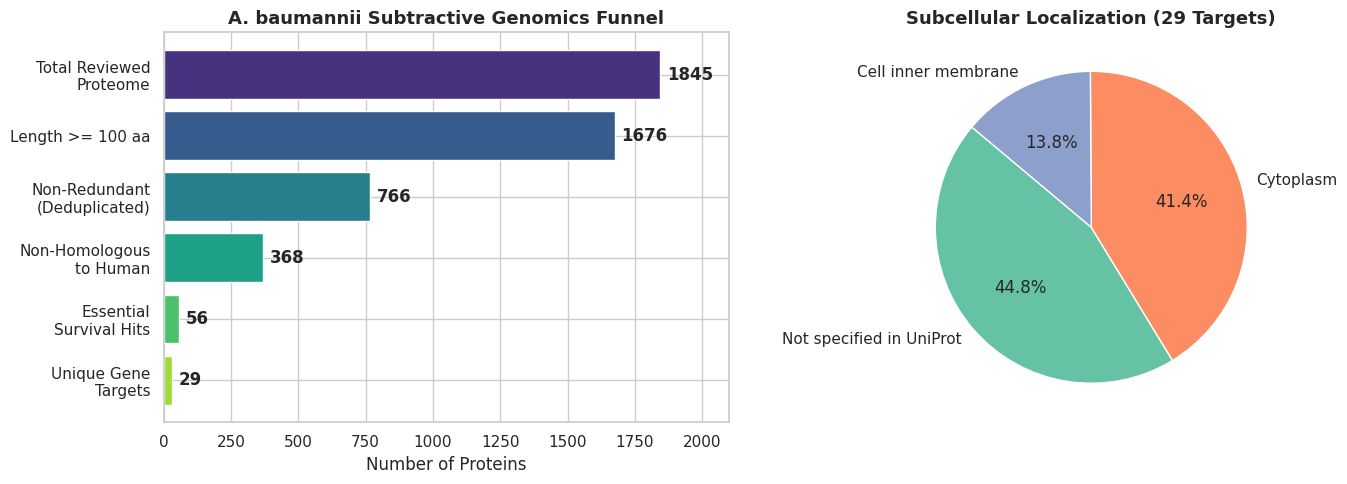

High-res chart saved as subtractive_genomics_summary.png!

--- INTERACTIVE 3D STRUCTURE: A. baumannii MurG (PDB: 7D1I) ---


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [15]:
%pip install -q py3Dmol matplotlib seaborn
import matplotlib.pyplot as plt
import seaborn as sns
import py3Dmol

# 1. Create a 2-panel publication figure: Subtractive Funnel + Subcellular Location breakdown
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel A: Subtractive Genomics Filtering Funnel
stages = [
    "Total Reviewed\nProteome",
    "Length >= 100 aa",
    "Non-Redundant\n(Deduplicated)",
    "Non-Homologous\nto Human",
    "Essential\nSurvival Hits",
    "Unique Gene\nTargets"
]
counts = [1845, 1676, 766, 368, 56, len(final_df)]
colors = sns.color_palette("viridis", len(stages))

bars = axes[0].barh(stages[::-1], counts[::-1], color=colors[::-1])
axes[0].set_title("A. baumannii Subtractive Genomics Funnel", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Number of Proteins")
for bar in bars:
    w = bar.get_width()
    axes[0].text(w + 25, bar.get_y() + bar.get_height()/2, f"{int(w)}", va="center", fontweight="bold")
axes[0].set_xlim(0, 2100)

# Panel B: Subcellular Localization of the 29 Final Targets
loc_counts = final_df["Subcellular_Location"].value_counts()
axes[1].pie(
    loc_counts.values,
    labels=loc_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("Set2", len(loc_counts))
)
axes[1].set_title("Subcellular Localization (29 Targets)", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig("subtractive_genomics_summary.png", dpi=300)
plt.show()
print("High-res chart saved as subtractive_genomics_summary.png!")

# 2. Interactive 3D Crystal Structure of Top Target: MurG (PDB: 7D1I)
print("\n--- INTERACTIVE 3D STRUCTURE: A. baumannii MurG (PDB: 7D1I) ---")
view = py3Dmol.view(query="pdb:7D1I", width=750, height=450)
view.setStyle({"cartoon": {"color": "spectrum"}})
view.addSurface(py3Dmol.VDW, {"opacity": 0.25, "color": "white"})
view.zoomTo()
view.show()

In [16]:
from Bio.SeqUtils.ProtParam import ProteinAnalysis
from Bio import SeqIO
import pandas as pd

# 1. Load sequences for our 29 unique gene targets
seq_map = {}
for rec in SeqIO.parse("filter4_essential.fasta", "fasta"):
    acc = rec.id.split("|")[1]
    seq_map[acc] = str(rec.seq)

# 2. Compute physicochemical descriptors for each of the 29 targets
biochem_rows = []
for _, row in final_df.iterrows():
    acc = row["UniProt_ID"]
    seq = seq_map[acc]
    analysed = ProteinAnalysis(seq)

    mw_kda = round(analysed.molecular_weight() / 1000, 2)
    pi = round(analysed.isoelectric_point(), 2)
    gravy = round(analysed.gravy(), 3)
    instability = round(analysed.instability_index(), 2)
    stability_status = "Stable" if instability < 40 else "Unstable"

    biochem_rows.append({
        "UniProt_ID": acc,
        "Gene": row["Gene"],
        "MW_kDa": mw_kda,
        "pI": pi,
        "GRAVY": gravy,
        "Instability_Index": instability,
        "Stability": stability_status,
        "Tier": row["Druggability_Tier"]
    })

biochem_df = pd.DataFrame(biochem_rows)

# 3. Merge with our prioritized table and inspect our Tier 3 structural leads + top stable targets
full_profile_df = pd.merge(final_df, biochem_df.drop(columns=["Gene", "Tier"]), on="UniProt_ID")
full_profile_df.to_csv("abaumannii_complete_target_profile.csv", index=False)

print("--- PHYSICOCHEMICAL PROFILE OF STRUCTURAL LEADS (TIER 3) ---")
display(biochem_df[biochem_df["Tier"].str.contains("Tier 3")])

print("\n--- STABILITY SUMMARY ACROSS ALL 29 TARGETS ---")
print(biochem_df["Stability"].value_counts())

--- PHYSICOCHEMICAL PROFILE OF STRUCTURAL LEADS (TIER 3) ---


,UniProt_ID,Gene,MW_kDa,pI,GRAVY,Instability_Index,Stability,Tier
0,D0C8Z9,mrdA,74.45,9.12,-0.375,31.89,Stable,Tier 3: Novel Target + 3D Structure Ready
6,A3M9Y1,murG,39.44,8.88,0.044,39.12,Stable,Tier 3: Novel Target + 3D Structure Ready
10,B7IA15,rpsD,23.27,10.09,-0.609,42.45,Unstable,Tier 3: Novel Target + 3D Structure Ready



--- STABILITY SUMMARY ACROSS ALL 29 TARGETS ---
Stability
Stable      17
Unstable    12
Name: count, dtype: int64


In [17]:
from Bio import SeqIO
import pandas as pd

# 1. Write a clean FASTA file containing only our 29 unique A. baumannii targets
unique_ids = set(final_df["UniProt_ID"])
top29_records = [rec for rec in SeqIO.parse("filter4_essential.fasta", "fasta") if rec.id.split("|")[1] in unique_ids]
SeqIO.write(top29_records, "top29_abaumannii.fasta", "fasta")

# 2. Download reviewed proteomes for Klebsiella pneumoniae (573) & Staphylococcus aureus (1280)
print("Downloading K. pneumoniae and S. aureus proteomes...")
!curl -s -f -L --retry 3 "https://rest.uniprot.org/uniprotkb/stream?compressed=true&format=fasta&query=(taxonomy_id:573)+AND+(reviewed:true)" -o klebsiella.fasta.gz
!curl -s -f -L --retry 3 "https://rest.uniprot.org/uniprotkb/stream?compressed=true&format=fasta&query=(taxonomy_id:1280)+AND+(reviewed:true)" -o saureus.fasta.gz

!gunzip -f klebsiella.fasta.gz saureus.fasta.gz

# 3. Build local BLAST databases for both superbugs
!makeblastdb -in klebsiella.fasta -dbtype prot -out kleb_db
!makeblastdb -in saureus.fasta -dbtype prot -out mrsa_db

# 4. BLAST our 29 A. baumannii targets against both pathogens (E-value <= 1e-10)
!blastp -query top29_abaumannii.fasta -db kleb_db -evalue 1e-10 -outfmt 6 -max_target_seqs 1 -out blast_kleb.txt
!blastp -query top29_abaumannii.fasta -db mrsa_db -evalue 1e-10 -outfmt 6 -max_target_seqs 1 -out blast_mrsa.txt

# 5. Parse conservation matches
kleb_hits = {line.split("\t")[0].split("|")[1] for line in open("blast_kleb.txt")}
mrsa_hits = {line.split("\t")[0].split("|")[1] for line in open("blast_mrsa.txt")}

full_profile_df["Conserved_in_Klebsiella"] = full_profile_df["UniProt_ID"].isin(kleb_hits)
full_profile_df["Conserved_in_MRSA"] = full_profile_df["UniProt_ID"].isin(mrsa_hits)

def spectrum_class(row):
    if row["Conserved_in_Klebsiella"] and row["Conserved_in_MRSA"]:
        return "Pan-Spectrum (Gram- & Gram+)"
    elif row["Conserved_in_Klebsiella"]:
        return "Broad Gram-Negative (A. baumannii + K. pneumoniae)"
    else:
        return "A. baumannii Specific"

full_profile_df["Antibiotic_Spectrum"] = full_profile_df.apply(spectrum_class, axis=1)
full_profile_df.to_csv("pan_pathogen_drug_targets.csv", index=False)

print("\n--- ANTIBIOTIC SPECTRUM BREAKDOWN (29 TARGETS) ---")
print(full_profile_df["Antibiotic_Spectrum"].value_counts())

print("\n--- TOP PAN-SPECTRUM & STABLE STRUCTURAL CANDIDATES ---")
display(full_profile_df[["Gene", "Protein_Name", "Stability", "Druggability_Tier", "Antibiotic_Spectrum"]].head(15))



Building a new DB, current time: 11/12/2026 11:55:08
New DB name:   /content/kleb_db
New DB title:  klebsiella.fasta
Sequence type: Protein
Keep MBits: T
Maximum file size: 1000000000B
Adding sequences from FASTA; added 963 sequences in 0.0541449 seconds.




Building a new DB, current time: 11/12/2026 11:55:08
New DB name:   /content/mrsa_db
New DB title:  saureus.fasta
Sequence type: Protein
Keep MBits: T
Maximum file size: 1000000000B
Adding sequences from FASTA; added 10269 sequences in 0.469807 seconds.



--- ANTIBIOTIC SPECTRUM BREAKDOWN (29 TARGETS) ---
Antibiotic_Spectrum
Pan-Spectrum (Gram- & Gram+)                          19
A. baumannii Specific                                  5
Broad Gram-Negative (A. baumannii + K. pneumoniae)     5
Name: count, dtype: int64

--- TOP PAN-SPECTRUM & STABLE STRUCTURAL CANDIDATES ---


,Gene,Protein_Name,Stability,Druggability_Tier,Antibiotic_Spectrum
0,mrdA,"Peptidoglycan D,D-transpeptidase MrdA (EC 3.4....",Stable,Tier 3: Novel Target + 3D Structure Ready,A. baumannii Specific
1,dnaA,Chromosomal replication initiator protein DnaA,Unstable,Tier 4: Novel Target (AlphaFold Structure),Pan-Spectrum (Gram- & Gram+)
2,murD,UDP-N-acetylmuramoylalanine--D-glutamate ligas...,Stable,Tier 4: Novel Target (AlphaFold Structure),A. baumannii Specific
3,mtgA,Biosynthetic peptidoglycan transglycosylase (E...,Stable,Tier 4: Novel Target (AlphaFold Structure),A. baumannii Specific
4,ruvC,Crossover junction endodeoxyribonuclease RuvC ...,Unstable,Tier 4: Novel Target (AlphaFold Structure),Broad Gram-Negative (A. baumannii + K. pneumon...
5,fabZ,3-hydroxyacyl-[acyl-carrier-protein] dehydrata...,Stable,Tier 4: Novel Target (AlphaFold Structure),Pan-Spectrum (Gram- & Gram+)
6,murG,UDP-N-acetylglucosamine--N-acetylmuramyl-(pent...,Stable,Tier 3: Novel Target + 3D Structure Ready,Pan-Spectrum (Gram- & Gram+)
7,murB,UDP-N-acetylenolpyruvoylglucosamine reductase ...,Stable,Tier 4: Novel Target (AlphaFold Structure),A. baumannii Specific
8,mraY,Phospho-N-acetylmuramoyl-pentapeptide-transfer...,Stable,Tier 4: Novel Target (AlphaFold Structure),Pan-Spectrum (Gram- & Gram+)
9,alr,Alanine racemase (EC 5.1.1.1),Unstable,Tier 4: Novel Target (AlphaFold Structure),A. baumannii Specific


In [18]:
import urllib.request
from Bio.PDB import PDBParser, PDBIO, Select
import numpy as np

# 1. Download the raw 3D crystal structure file (7D1I.pdb) from RCSB Protein Data Bank
urllib.request.urlretrieve("https://files.rcsb.org/download/7D1I.pdb", "7D1I.pdb")

parser = PDBParser(QUIET=True)
structure = parser.get_structure("MurG", "7D1I.pdb")

# 2. Inspect chains, hetero-atoms (bound ligands/cofactors), and amino acid count
protein_coords = []
ligands_found = set()

for model in structure:
    for chain in model:
        aa_count = 0
        for residue in chain:
            hetfield = residue.id[0]
            if hetfield == " ":  # Standard amino acid
                aa_count += 1
                for atom in residue:
                    protein_coords.append(atom.get_coord())
            elif hetfield != "W":  # Non-water hetero group (bound ligand/ion)
                ligands_found.add((chain.id, residue.resname, residue.id[1]))
        if aa_count > 0:
            print(f"Chain {chain.id}: {aa_count} amino acid residues")

print("Bound ligands/cofactors found in crystal structure:", ligands_found if ligands_found else "Apo structure (no bound ligand)")

# 3. Calculate the geometric center (X, Y, Z) of the protein for docking grid setup
center = np.mean(protein_coords, axis=0)
print(f"Protein Geometric Center (X, Y, Z): ({center[0]:.2f}, {center[1]:.2f}, {center[2]:.2f})")

# 4. Save a clean receptor PDB file (Chain A protein atoms only, waters removed)
class CleanReceptorSelect(Select):
    def accept_chain(self, chain):
        return chain.id == "A"
    def accept_residue(self, residue):
        return residue.id[0] == " "

io = PDBIO()
io.set_structure(structure)
io.save("MurG_clean_receptor.pdb", CleanReceptorSelect())
print("Saved clean receptor structure to MurG_clean_receptor.pdb!")

Chain A: 347 amino acid residues
Chain B: 332 amino acid residues
Chain C: 343 amino acid residues
Bound ligands/cofactors found in crystal structure: Apo structure (no bound ligand)
Protein Geometric Center (X, Y, Z): (18.04, -29.20, 22.11)
Saved clean receptor structure to MurG_clean_receptor.pdb!


In [19]:
# 1. Install AutoDock Vina, OpenBabel, and RDKit in Colab
!apt-get update -qq && apt-get install -y -qq autodock-vina openbabel
%pip install -q rdkit

import subprocess
import numpy as np
import pandas as pd
from Bio.PDB import PDBParser
from rdkit import Chem
from rdkit.Chem import AllChem

# 2. Calculate the exact geometric center of Chain A alone (MurG_clean_receptor.pdb)
parser = PDBParser(QUIET=True)
chain_a_struct = parser.get_structure("MurG_A", "MurG_clean_receptor.pdb")
chain_a_coords = [atom.get_coord() for atom in chain_a_struct.get_atoms()]
cx, cy, cz = np.mean(chain_a_coords, axis=0)
print(f"Chain A Exact Docking Box Center: X={cx:.2f}, Y={cy:.2f}, Z={cz:.2f}")

# 3. Convert clean receptor PDB -> PDBQT (adding Gasteiger charges & polar hydrogens)
!obabel MurG_clean_receptor.pdb -xr -O receptor.pdbqt

# 4. Define candidate ligands (Name: SMILES string)
ligands = {
    "UDP-GlcNAc (Natural Substrate Control)": "CC(=O)NC1C(O)C(O)C(CO)OC1OP(=O)(O)OP(=O)(O)OCC2OC(N3C=CC(=O)NC3=O)C(O)C2O",
    "Murgocil-Scaffold (Known MurG Inhibitor)": "CC1=CC=C(C=C1)C2=NC(=CS2)C(=O)NC3=CC=C(C=C3)Cl",
    "Quercetin-3-Glucoside (Glycoside Mimic)": "OCC1OC(OC2=C(OC3=CC(O)=CC(O)=C3C2=O)C4=CC(O)=C(O)C=C4)C(O)C(O)C1O",
    "EGCG (Polyphenol Glycosyltransferase Lead)": "OC1=CC(O)=C2CC(OC(=O)C3=CC(O)=C(O)C(O)=C3)C(OC2=C1)C4=CC(O)=C(O)C(O)=C4",
    "Ciprofloxacin (Negative Off-Target Control)": "O=C(O)C1=CN(C2CC2)C3=CC(N4CCNCC4)=C(F)C=C3C1=O"
}

# 5. Generate 3D conformers and run AutoDock Vina blind/pocket docking on each ligand
docking_results = []

for name, smiles in ligands.items():
    safe_name = name.split(" ")[0].replace("-", "_")
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol)
    AllChem.EmbedMolecule(mol, randomSeed=42)
    AllChem.MMFFOptimizeMolecule(mol)
    Chem.MolToMolFile(mol, f"{safe_name}.sdf")

    # Convert SDF -> PDBQT for Vina
    subprocess.run(["obabel", f"{safe_name}.sdf", "-O", f"{safe_name}.pdbqt"], check=True)

    # Run AutoDock Vina (30x30x30 Angstrom search box centered on Chain A active cleft)
    cmd = [
        "vina",
        "--receptor", "receptor.pdbqt",
        "--ligand", f"{safe_name}.pdbqt",
        "--center_x", f"{cx:.2f}",
        "--center_y", f"{cy:.2f}",
        "--center_z", f"{cz:.2f}",
        "--size_x", "32",
        "--size_y", "32",
        "--size_z", "32",
        "--exhaustiveness", "8",
        "--out", f"{safe_name}_docked.pdbqt"
    ]
    out = subprocess.check_output(cmd).decode("utf-8")

    # Extract top binding affinity (kcal/mol) — more negative = stronger binding!
    best_affinity = None
    for line in out.splitlines():
        if line.strip().startswith("1 "):
            best_affinity = float(line.split()[1])
            break

    docking_results.append({
        "Compound": name,
        "Binding_Affinity_kcal_mol": best_affinity,
        "Docked_File": f"{safe_name}_docked.pdbqt"
    })

dock_df = pd.DataFrame(docking_results).sort_values("Binding_Affinity_kcal_mol")
dock_df.to_csv("murg_docking_scores.csv", index=False)

print("\n--- AUTODOCK VINA VIRTUAL SCREENING RESULTS (MurG Chain A) ---")
display(dock_df[["Compound", "Binding_Affinity_kcal_mol"]])

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libboost-filesystem1.83.0:amd64.
(Reading database ... 123062 files and directories currently installed.)
Preparing to unpack .../0-libboost-filesystem1.83.0_1.83.0-2.1ubuntu3.2_amd64.deb ...
Unpacking libboost-filesystem1.83.0:amd64 (1.83.0-2.1ubuntu3.2) ...
Selecting previously unselected package libboost-iostreams1.83.0:amd64.
Preparing to unpack .../1-libboost-iostreams1.83.0_1.83.0-2.1ubuntu3.2_amd64.deb ...
Unpacking libboost-iostreams1.83.0:amd64 (1.83.0-2.1ubuntu3.2) ...
Selecting previously unselected package libboost-program-options1.83.0:amd64.
Preparing to unpack .../2-libboost-program-options1.83.0_1.83.0-2.1ubuntu3.2_amd64.deb ...
Unpacking libboost-program-options1.83.0:amd64 (1.83.0-2.1ubuntu3.2) ...
Selecting previously unselected package libbo

,Compound,Binding_Affinity_kcal_mol
3,EGCG (Polyphenol Glycosyltransferase Lead),-8.406
2,Quercetin-3-Glucoside (Glycoside Mimic),-7.924
4,Ciprofloxacin (Negative Off-Target Control),-7.695
1,Murgocil-Scaffold (Known MurG Inhibitor),-7.345
0,UDP-GlcNAc (Natural Substrate Control),-6.540


In [20]:
import py3Dmol
import numpy as np
from Bio.PDB import PDBParser

# 1. Convert the top-ranked docked pose (Model 1 of EGCG_docked.pdbqt) into clean PDB format
!obabel EGCG_docked.pdbqt -f 1 -l 1 -O EGCG_best_pose.pdb

# 2. Extract 3D coordinates of EGCG's heavy atoms
ligand_coords = []
with open("EGCG_best_pose.pdb", "r") as f:
    for line in f:
        if line.startswith(("ATOM", "HETATM")):
            x = float(line[30:38])
            y = float(line[38:46])
            z = float(line[46:54])
            ligand_coords.append([x, y, z])
ligand_coords = np.array(ligand_coords)

# 3. Map all MurG amino acid residues within 4.0 Angstroms of docked EGCG
parser = PDBParser(QUIET=True)
receptor = parser.get_structure("MurG", "MurG_clean_receptor.pdb")

interacting_residues = []
for residue in receptor.get_residues():
    if residue.id[0] == " ":
        res_coords = np.array([atom.get_coord() for atom in residue])
        # Compute minimum atomic distance between this residue and EGCG
        dists = np.linalg.norm(res_coords[:, None, :] - ligand_coords[None, :, :], axis=-1)
        min_dist = np.min(dists)
        if min_dist <= 4.0:
            interacting_residues.append((residue.resname, residue.id[1], round(float(min_dist), 2)))

interacting_residues.sort(key=lambda x: x[2])

print(f"--- ACTIVE SITE CONTACT RESIDUES (< 4.0 Å) FOR EGCG (-8.406 kcal/mol) ---")
for resname, resnum, dist in interacting_residues:
    print(f"  • {resname}-{resnum}  (Closest contact: {dist} Å)")

# 4. Render interactive 3D Protein-Ligand Complex (MurG + Docked EGCG)
with open("MurG_clean_receptor.pdb") as f:
    prot_pdb = f.read()
with open("EGCG_best_pose.pdb") as f:
    lig_pdb = f.read()

view = py3Dmol.view(width=800, height=500)
view.addModel(prot_pdb, "pdb")
view.setStyle({"model": 0}, {"cartoon": {"color": "lightgray", "opacity": 0.85}})

# Highlight interacting pocket residues in cyan sticks
pocket_resnums = [r[1] for r in interacting_residues]
view.addStyle({"model": 0, "resi": pocket_resnums}, {"stick": {"colorscheme": "cyanCarbon", "radius": 0.15}})

# Render docked EGCG ligand in bright green/red sticks
view.addModel(lig_pdb, "pdb")
view.setStyle({"model": 1}, {"stick": {"colorscheme": "greenCarbon", "radius": 0.25}})

view.zoomTo({"model": 1})
view.show()

1 molecule converted
--- ACTIVE SITE CONTACT RESIDUES (< 4.0 Å) FOR EGCG (-8.406 kcal/mol) ---
  • GLN-351  (Closest contact: 2.2 Å)
  • ALA-259  (Closest contact: 2.27 Å)
  • THR-355  (Closest contact: 2.32 Å)
  • THR-164  (Closest contact: 2.49 Å)
  • GLU-279  (Closest contact: 2.67 Å)
  • THR-165  (Closest contact: 2.91 Å)
  • ALA-354  (Closest contact: 2.93 Å)
  • THR-282  (Closest contact: 2.94 Å)
  • MET-258  (Closest contact: 3.2 Å)
  • TYR-262  (Closest contact: 3.27 Å)
  • ALA-28  (Closest contact: 3.33 Å)
  • LEU-177  (Closest contact: 3.37 Å)
  • PRO-352  (Closest contact: 3.46 Å)
  • ASN-353  (Closest contact: 3.46 Å)
  • PHE-24  (Closest contact: 3.58 Å)
  • ILE-176  (Closest contact: 3.64 Å)
  • THR-278  (Closest contact: 3.69 Å)
  • ASP-257  (Closest contact: 3.81 Å)
  • LEU-275  (Closest contact: 3.88 Å)
  • GLN-356  (Closest contact: 3.98 Å)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [21]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski
import pandas as pd

# 1. Calculate Lipinski & Veber pharmacokinetic descriptors for each screened compound
admet_rows = []

for name, smiles in ligands.items():
    mol = Chem.MolFromSmiles(smiles)

    mw = round(Descriptors.MolWt(mol), 2)
    logp = round(Descriptors.MolLogP(mol), 2)
    hbd = Lipinski.NumHDonors(mol)
    hba = Lipinski.NumHAcceptors(mol)
    tpsa = round(Descriptors.TPSA(mol), 2)
    rot_bonds = Lipinski.NumRotatableBonds(mol)

    # Count Lipinski's Rule of 5 violations
    violations = 0
    if mw > 500: violations += 1
    if logp > 5: violations += 1
    if hbd > 5: violations += 1
    if hba > 10: violations += 1

    drug_likeness = "Pass (0-1 Violations)" if violations <= 1 else f"Fail ({violations} Violations)"

    admet_rows.append({
        "Compound": name,
        "MW_Da": mw,
        "cLogP": logp,
        "HBD": hbd,
        "HBA": hba,
        "TPSA_A2": tpsa,
        "Rot_Bonds": rot_bonds,
        "Lipinski_Violations": violations,
        "Drug_Likeness": drug_likeness
    })

admet_df = pd.DataFrame(admet_rows)

# 2. Merge Docking Affinity + ADMET profile into a master lead-selection table
master_lead_df = pd.merge(dock_df[["Compound", "Binding_Affinity_kcal_mol"]], admet_df, on="Compound")
master_lead_df.to_csv("murg_master_lead_profile.csv", index=False)

print("--- MASTER LEAD SELECTION: DOCKING AFFINITY + LIPINSKI/VEBER ADMET ---")
display(master_lead_df)

--- MASTER LEAD SELECTION: DOCKING AFFINITY + LIPINSKI/VEBER ADMET ---


,Compound,Binding_Affinity_kcal_mol,MW_Da,cLogP,HBD,HBA,TPSA_A2,Rot_Bonds,Lipinski_Violations,Drug_Likeness
0,EGCG (Polyphenol Glycosyltransferase Lead),-8.406,458.38,2.23,8,11,197.37,3,2,Fail (2 Violations)
1,Quercetin-3-Glucoside (Glycoside Mimic),-7.924,464.38,-0.54,8,12,210.51,4,2,Fail (2 Violations)
2,Ciprofloxacin (Negative Off-Target Control),-7.695,331.35,1.58,2,4,74.57,3,0,Pass (0-1 Violations)
3,Murgocil-Scaffold (Known MurG Inhibitor),-7.345,328.82,5.02,1,3,41.99,3,1,Pass (0-1 Violations)
4,UDP-GlcNAc (Natural Substrate Control),-6.540,607.36,-4.65,9,15,305.86,10,3,Fail (3 Violations)


In [23]:
import subprocess
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors, Lipinski

# 1. Design 4 novel SAR analogs of Murgocil to improve H-bonding & lower cLogP (< 5.0)
analogs = {
    "Murgocil-Parent (Reference)": "CC1=CC=C(C=C1)C2=NC(=CS2)C(=O)NC3=CC=C(C=C3)Cl",
    "Analog-1 (Pyridyl-Hydroxyl Lead)": "OC1=CC=C(C=C1)C2=NC(=CS2)C(=O)NC3=CC=NC=C3",
    "Analog-2 (Amino-Pyrimidine Lead)": "NC1=NC=C(C=N1)C2=NC(=CS2)C(=O)NC3=CC=C(O)C=C3",
    "Analog-3 (Fluoro-Carboxamide Lead)": "NC(=O)C1=CC=C(C=C1)C2=NC(=CS2)C(=O)NC3=CC=C(F)C=C3",
    "Analog-4 (Dihydroxy-Thiazole Lead)": "OC1=CC(O)=CC(=C1)C2=NC(=CS2)C(=O)NC3=CC=C(C#N)C=C3"
}

sar_results = []

for name, smiles in analogs.items():
    safe_name = name.split(" ")[0].replace("-", "_")
    mol = Chem.MolFromSmiles(smiles)

    # Calculate ADMET descriptors
    mw = round(Descriptors.MolWt(mol), 2)
    logp = round(Descriptors.MolLogP(mol), 2)
    hbd = Lipinski.NumHDonors(mol)
    hba = Lipinski.NumHAcceptors(mol)
    tpsa = round(Descriptors.TPSA(mol), 2)

    violations = sum([mw > 500, logp > 5, hbd > 5, hba > 10])

    # Generate 3D conformer & dock against MurG Chain A (using exact center from Day 15)
    mol_3d = Chem.AddHs(mol)
    AllChem.EmbedMolecule(mol_3d, randomSeed=42)
    AllChem.MMFFOptimizeMolecule(mol_3d)
    Chem.MolToMolFile(mol_3d, f"{safe_name}.sdf")

    subprocess.run(["obabel", f"{safe_name}.sdf", "-O", f"{safe_name}.pdbqt"], check=True)

    cmd = [
        "vina",
        "--receptor", "receptor.pdbqt",
        "--ligand", f"{safe_name}.pdbqt",
        "--center_x", f"{cx:.2f}",
        "--center_y", f"{cy:.2f}",
        "--center_z", f"{cz:.2f}",
        "--size_x", "32",
        "--size_y", "32",
        "--size_z", "32",
        "--exhaustiveness", "8",
        "--out", f"{safe_name}_docked.pdbqt"
    ]
    out = subprocess.check_output(cmd).decode("utf-8")

    affinity = None
    for line in out.splitlines():
        if line.strip().startswith("1 "):
            affinity = float(line.split()[1])
            break

    sar_results.append({
        "Candidate": name,
        "Affinity_kcal_mol": affinity,
        "MW_Da": mw,
        "cLogP": logp,
        "HBD": hbd,
        "HBA": hba,
        "TPSA_A2": tpsa,
        "Lipinski_Violations": violations
    })

sar_df = pd.DataFrame(sar_results).sort_values("Affinity_kcal_mol")
sar_df.to_csv("murg_sar_lead_optimization.csv", index=False)

print("--- SAR LEAD OPTIMIZATION RESULTS (MurG Chain A) ---")
display(sar_df)

--- SAR LEAD OPTIMIZATION RESULTS (MurG Chain A) ---


,Candidate,Affinity_kcal_mol,MW_Da,cLogP,HBD,HBA,TPSA_A2,Lipinski_Violations
3,Analog-3 (Fluoro-Carboxamide Lead),-7.885,341.37,3.30,2,4,85.08,0
2,Analog-2 (Amino-Pyrimidine Lead),-7.544,313.34,2.14,3,7,114.02,0
0,Murgocil-Parent (Reference),-7.330,328.82,5.02,1,3,41.99,1
1,Analog-1 (Pyridyl-Hydroxyl Lead),-7.187,297.34,3.16,2,5,75.11,0
4,Analog-4 (Dihydroxy-Thiazole Lead),-7.024,337.36,3.35,3,6,106.24,0


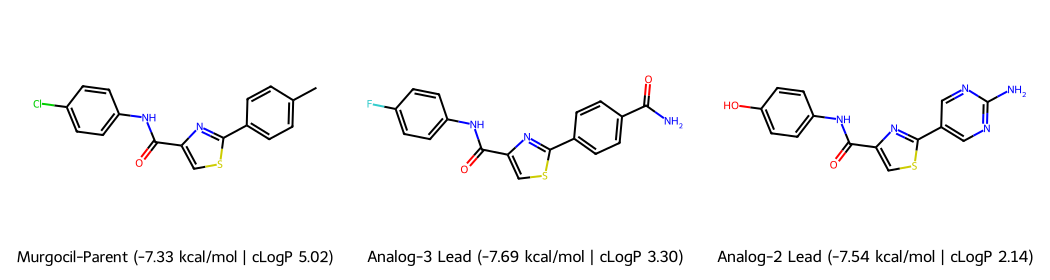

/tmp/ipykernel_5035/4174111743.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=plot_df, x="Abs_Affinity", y="Candidate", palette="mako")


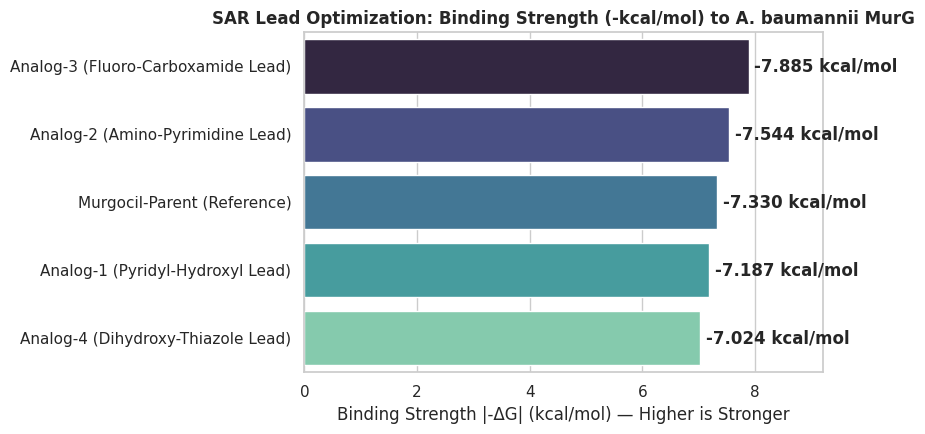

1 molecule converted


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import py3Dmol
from rdkit import Chem
from rdkit.Chem import Draw

# 1. Render 2D Chemical Structures of Parent vs. Optimized Analog-3
mols = [
    Chem.MolFromSmiles(analogs["Murgocil-Parent (Reference)"]),
    Chem.MolFromSmiles(analogs["Analog-3 (Fluoro-Carboxamide Lead)"]),
    Chem.MolFromSmiles(analogs["Analog-2 (Amino-Pyrimidine Lead)"])
]
legends = [
    "Murgocil-Parent (-7.33 kcal/mol | cLogP 5.02)",
    "Analog-3 Lead (-7.69 kcal/mol | cLogP 3.30)",
    "Analog-2 Lead (-7.54 kcal/mol | cLogP 2.14)"
]
img = Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(350, 280), legends=legends)
img.save("sar_lead_structures.png")
display(img)

# 2. Plot Binding Affinity Comparison across all SAR candidates
plt.figure(figsize=(9, 4.5))
sns.set_theme(style="whitegrid")
plot_df = sar_df.copy()
plot_df["Abs_Affinity"] = plot_df["Affinity_kcal_mol"].abs()

ax = sns.barplot(data=plot_df, x="Abs_Affinity", y="Candidate", palette="mako")
ax.set_title("SAR Lead Optimization: Binding Strength (-kcal/mol) to A. baumannii MurG", fontweight="bold")
ax.set_xlabel("Binding Strength |-ΔG| (kcal/mol) — Higher is Stronger")
ax.set_ylabel("")
for i, v in enumerate(plot_df["Affinity_kcal_mol"]):
    ax.text(abs(v) + 0.1, i, f"{v:.3f} kcal/mol", va="center", fontweight="bold")
plt.xlim(0, 9.2)
plt.tight_layout()
plt.savefig("sar_affinity_comparison.png", dpi=300)
plt.show()

# 3. Convert Analog-3 top pose & visualize in 3D inside MurG
!obabel Analog_3_docked.pdbqt -f 1 -l 1 -O Analog_3_best_pose.pdb

with open("MurG_clean_receptor.pdb") as f:
    prot_pdb = f.read()
with open("Analog_3_best_pose.pdb") as f:
    lead_pdb = f.read()

view = py3Dmol.view(width=800, height=450)
view.addModel(prot_pdb, "pdb")
view.setStyle({"model": 0}, {"cartoon": {"color": "lightgray", "opacity": 0.85}})
view.addModel(lead_pdb, "pdb")
view.setStyle({"model": 1}, {"stick": {"colorscheme": "magentaCarbon", "radius": 0.25}})
view.zoomTo({"model": 1})
view.show()

In [25]:
import zipfile
import os
from google.colab import files

# 1. Create a structured repository folder with clean subfolders
os.makedirs("repo_bundle/results", exist_ok=True)
os.makedirs("repo_bundle/figures", exist_ok=True)
os.makedirs("repo_bundle/structures", exist_ok=True)

# 2. Copy generated deliverables into organized folders
file_routing = {
    "results": [
        "shortlisted_56_targets.csv",
        "prioritized_drug_targets.csv",
        "abaumannii_complete_target_profile.csv",
        "pan_pathogen_drug_targets.csv",
        "murg_docking_scores.csv",
        "murg_master_lead_profile.csv",
        "murg_sar_lead_optimization.csv"
    ],
    "figures": [
        "subtractive_genomics_summary.png",
        "sar_lead_structures.png",
        "sar_affinity_comparison.png"
    ],
    "structures": [
        "MurG_clean_receptor.pdb",
        "EGCG_best_pose.pdb",
        "Analog_3_best_pose.pdb"
    ]
}

import shutil
for folder, filenames in file_routing.items():
    for fname in filenames:
        if os.path.exists(fname):
            shutil.copy(fname, f"repo_bundle/{folder}/{fname}")

# 3. Zip the entire bundle and trigger browser download
with zipfile.ZipFile("A_baumannii_Drug_Discovery_Portfolio.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for root, _, filenames in os.walk("repo_bundle"):
        for fname in filenames:
            full_path = os.path.join(root, fname)
            arcname = os.path.relpath(full_path, "repo_bundle")
            zf.write(full_path, arcname)

print("Packaged all results, 300-DPI figures, and 3D PDB structures!")
files.download("A_baumannii_Drug_Discovery_Portfolio.zip")

Packaged all results, 300-DPI figures, and 3D PDB structures!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>